# K-Means vs DBSCAN on Kenyan sub-county demographics (2019 census)

This notebook compares two clustering algorithms on 333 Kenyan sub-counties. The data comes from the 2019 Kenya Population and Housing Census (KNBS), as packaged in the open [rKenyaCensus](https://github.com/Shelmith-Kariuki/rKenyaCensus) repository (MIT licence).

Each sub-county is described by eight indicators covering population, households, services and technology. No labels exist, so the clusters are judged with internal quality scores, stability and runtime.

## 1. Setup
The libraries are loaded and a fixed random seed is set so the results repeat exactly.

In [1]:
import re, time, json, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, pyreadr
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
import sklearn
SEED = 42
DATA = Path('data'); FIG = Path('figures')
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


## 2. Download the census tables
Eight small tables are needed. Each one is downloaded only if it is not already in `data/`.

In [2]:
TABLES = {
    'V1_T2.6': 'Population, households and average household size by sub-county',
    'V1_T2.7': 'Land area and population density by sub-county',
    'V3_T2.3': 'Population by single year of age and sub-county',
    'V4_T2.15': 'Main source of drinking water (% of households)',
    'V4_T2.18': 'Main cooking fuel (% of households)',
    'V4_T2.19': 'Main lighting fuel (% of households)',
    'V4_T2.32': 'Mobile phone ownership, age 3+ (%)',
    'V4_T2.33': 'Internet use, age 3+ (%)',
}
BASE = 'https://raw.githubusercontent.com/Shelmith-Kariuki/rKenyaCensus/master/data/'
for t in TABLES:
    f = DATA / f'{t}.rda'
    if not f.exists():
        urllib.request.urlretrieve(BASE + f.name, f)
def read(t):
    return next(iter(pyreadr.read_r(str(DATA / f'{t}.rda')).values()))
print('\n'.join(f'{t}: {d}' for t, d in TABLES.items()))

V1_T2.6: Population, households and average household size by sub-county
V1_T2.7: Land area and population density by sub-county
V3_T2.3: Population by single year of age and sub-county
V4_T2.15: Main source of drinking water (% of households)
V4_T2.18: Main cooking fuel (% of households)
V4_T2.19: Main lighting fuel (% of households)
V4_T2.32: Mobile phone ownership, age 3+ (%)
V4_T2.33: Internet use, age 3+ (%)


## 3. Join the tables into one row per sub-county
Names are written differently across tables (for example "Nairobi City" and "Nairobi", or "Samburu-Kwale" and "Samburu"). A cleaning function removes case, spaces and punctuation. A few known spellings are mapped by hand, and names cut short in the age table are matched by their start.

In [3]:
def norm(s):
    return re.sub(r'[^A-Z]', '', str(s).upper().replace('COUNTY', '').replace('CITY', ''))
ALIAS = {'BUNGOMA|KIMILILIBUNGOMA': 'BUNGOMA|KIMILILI', 'MANDERA|KUTULO': 'MANDERA|KOTULO',
         'KWALE|SAMBURU': 'KWALE|SAMBURUKWALE'}
def key(df):
    k = df.County.map(norm) + '|' + df.SubCounty.map(norm)
    return k.replace(ALIAS)
def sub(t):
    df = read(t); df = df[df.AdminArea == 'SubCounty'].copy(); df['k'] = key(df)
    return df.set_index('k')

light, water, cook = sub('V4_T2.19'), sub('V4_T2.15'), sub('V4_T2.18')
phone, net = sub('V4_T2.32'), sub('V4_T2.33')
hh, dens = sub('V1_T2.6'), sub('V1_T2.7')

df = pd.DataFrame({
    'county': light.County.str.title(), 'subcounty': light.SubCounty.str.title(),
    'households': light.ConventionalHouseholds,
    'electricity_pct': light.MainsElectricity,
    'piped_water_pct': water['Pipedintodwelling'] + water['Pipedtoyard/Plot'],
    'firewood_pct': cook.Firewood,
    'mobile_phone_pct': phone.MPO_Total_Perc,
    'internet_pct': net.UoI_Total_Perc,
})
df['household_size'] = hh.AverageHouseholdSize
df['density'] = dens['Population Density(No. per Sq. Km)']

# share of people under 15 from the single-year age table
age = read('V3_T2.3'); age = age[age.SubCounty != 'ALL'].copy(); age['k'] = key(age)
yrs = age[age.Age.str.fullmatch(r'\d+')].copy(); yrs['a'] = yrs.Age.astype(int)
tot = age[age.Age == 'Total'].groupby('k').Total.sum()
u15 = yrs[yrs.a < 15].groupby('k').Total.sum()
under15 = (100 * u15 / tot).rename('under15_pct')
fix = {}
for k in under15.index.difference(df.index):          # names cut short in the age table
    c, s = k.split('|')
    hits = [i for i in df.index if i.startswith(c + '|') and i.split('|')[1].startswith(s)]
    if len(hits) == 1: fix[k] = hits[0]
df = df.join(under15.rename(index=fix))

print('sub-counties in census tables:', len(df))
small = df[df.households < 1000]
print('dropped forests/parks with under 1,000 households:', len(small), '->', ', '.join(small.subcounty))
df = df[df.households >= 1000].dropna()
print('final rows:', len(df), '| missing values:', int(df.isna().sum().sum()))
df.reset_index(drop=True).to_csv(DATA / 'kenya_subcounty_2019.csv', index=False)

sub-counties in census tables: 345
dropped forests/parks with under 1,000 households: 11 -> Meru National Park, Mt. Kenya Forest, Mt. Kenya Forest, Mt. Kenya Forest, Aberdare National Park, Mt. Kenya Forest, Aberdare Forest, Mt. Kenya Forest, Aberdare Forest, Kakamega Forest, Mt. Elgon Forest
final rows: 333 | missing values: 0


## 4. Choose and scale the features
Eight indicators are used. Population density is very skewed (from about 1 to over 60,000 people per km²), so its log is taken. All features are then standardised to mean 0 and standard deviation 1, so that no single unit dominates the distance.

In [4]:
FEATS = ['log_density', 'household_size', 'under15_pct', 'electricity_pct',
         'piped_water_pct', 'firewood_pct', 'internet_pct', 'mobile_phone_pct']
df['log_density'] = np.log10(df.density)
X = StandardScaler().fit_transform(df[FEATS])
print(df[FEATS + ['density']].describe().T[['mean', 'min', 'max']].round(1))
print('\nStrongest correlations:')
cor = df[FEATS].corr().where(np.triu(np.ones((8, 8)), 1).astype(bool)).stack().dropna().sort_values()
print(pd.concat([cor.head(3), cor.tail(3)]).round(2))

                    mean   min      max
log_density          2.4   0.5      4.8
household_size       4.3   2.7      7.7
under15_pct         39.9  25.3     59.0
electricity_pct     36.8   0.1     97.1
piped_water_pct     17.6   0.0     87.2
firewood_pct        69.5   0.2     98.4
internet_pct        18.8   2.6     65.9
mobile_phone_pct    44.5   5.9     75.7
density           1056.6   3.0  68941.0

Strongest correlations:
under15_pct      mobile_phone_pct   -0.92
firewood_pct     internet_pct       -0.90
household_size   mobile_phone_pct   -0.88
electricity_pct  mobile_phone_pct    0.85
internet_pct     mobile_phone_pct    0.86
electricity_pct  internet_pct        0.90
dtype: float64


## 5. K-Means: choose the number of clusters
K-Means needs k chosen in advance. k from 2 to 8 is tried, and inertia (the elbow method) and the silhouette score are compared. The silhouette ranges from -1 to 1, and higher means tighter, better separated clusters.

    inertia  silhouette  davies_bouldin
k                                      
2  1312.021       0.466           0.869
3   909.945       0.384           0.925
4   667.438       0.386           0.916
5   585.231       0.292           1.133
6   531.495       0.298           1.176
7   482.967       0.264           1.205
8   454.020       0.270           1.230


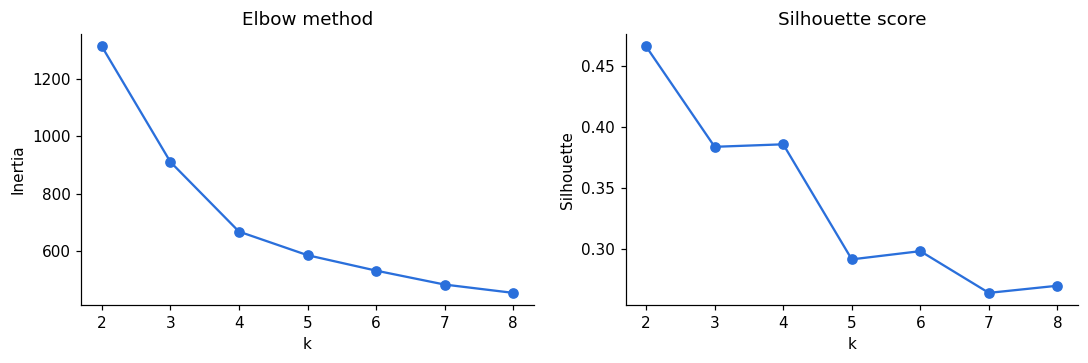

In [5]:
ks = range(2, 9); rows = []
for k in ks:
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                 'davies_bouldin': davies_bouldin_score(X, km.labels_)})
ksel = pd.DataFrame(rows).set_index('k'); print(ksel.round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(ksel.index, ksel.inertia, 'o-', color='#2a6fdb'); ax[0].set(title='Elbow method', xlabel='k', ylabel='Inertia')
ax[1].plot(ksel.index, ksel.silhouette, 'o-', color='#2a6fdb'); ax[1].set(title='Silhouette score', xlabel='k', ylabel='Silhouette')
plt.tight_layout(); plt.savefig(FIG / 'kmeans_k_selection.png', bbox_inches='tight'); plt.show()

k = 2 gives the highest silhouette but only splits urban from rural, which is too coarse to be useful. k = 3 sits at the elbow. k = 3 and k = 4 have almost the same silhouette (0.384 and 0.386), and k = 3 is easier to explain, so it is used for the comparison below. (Section 7 also reports k = 2 for fairness.)

In [6]:
K = 3
km = KMeans(K, n_init=20, random_state=SEED).fit(X)
df['kmeans'] = km.labels_
# name each K-Means cluster by its median electricity access (lowest to highest)
order = df.groupby('kmeans').electricity_pct.median().sort_values().index
LABELS = dict(zip(order, ['Remote and underserved', 'Rural farming', 'Urban and peri-urban']))
print(df.kmeans.map(LABELS).value_counts())

kmeans
Rural farming             175
Urban and peri-urban       84
Remote and underserved     74
Name: count, dtype: int64


## 6. DBSCAN: choose eps and min_samples
DBSCAN needs a neighbourhood radius (eps) and a minimum number of neighbours (min_samples). A common rule is min_samples = 2 × number of features = 16. The k-distance plot shows each point's distance to its 16th nearest neighbour. The bend in the curve suggests a value for eps. A small grid is then searched.

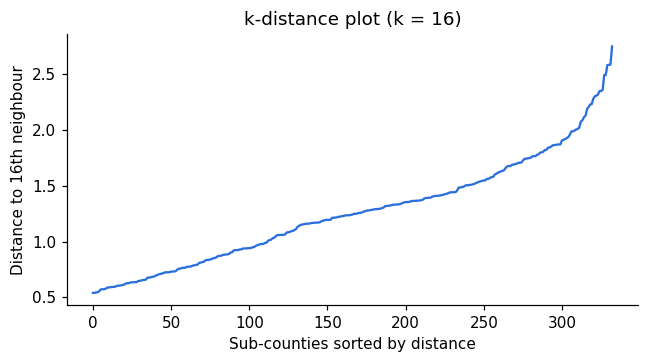

Best settings with at least 2 clusters and at most 25% noise:
 min_samples  eps  clusters  noise_pct  silhouette_core
          12  1.4         2      7.808            0.518
           5  1.2         2      6.607            0.515
           8  1.3         2      8.108            0.513
           5  1.3         2      5.405            0.512
           8  1.4         2      4.505            0.510
          12  1.5         2      4.805            0.506
          12  1.6         2      2.102            0.502
          16  1.7         2      3.003            0.500

min_samples = 16 across eps:
 min_samples  eps  clusters  noise_pct  silhouette_core
          16  0.8         2     64.865            0.349
          16  1.0         1     54.054              NaN
          16  1.2         1     29.730              NaN
          16  1.4         1     14.715              NaN
          16  1.6         2      5.706            0.487
          16  1.8         1      1.201              NaN
          16

In [7]:
MS = 2 * len(FEATS)
d = np.sort(NearestNeighbors(n_neighbors=MS).fit(X).kneighbors(X)[0][:, -1])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(d, color='#2a6fdb'); ax.set(title=f'k-distance plot (k = {MS})', xlabel='Sub-counties sorted by distance', ylabel=f'Distance to {MS}th neighbour')
plt.tight_layout(); plt.savefig(FIG / 'dbscan_k_distance.png', bbox_inches='tight'); plt.show()

grid = []
for ms in [5, 8, 12, 16]:
    for eps in np.round(np.arange(0.8, 3.01, 0.1), 2):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n = len(set(lab) - {-1}); mask = lab != -1
        sil = silhouette_score(X[mask], lab[mask]) if n >= 2 else np.nan
        grid.append({'min_samples': ms, 'eps': eps, 'clusters': n, 'noise_pct': 100 * (~mask).mean(), 'silhouette_core': sil})
grid = pd.DataFrame(grid)
ok = grid[(grid.clusters >= 2) & (grid.noise_pct <= 25)].sort_values('silhouette_core', ascending=False)
print('Best settings with at least 2 clusters and at most 25% noise:'); print(ok.head(8).round(3).to_string(index=False))
print('\nmin_samples = 16 across eps:'); print(grid[grid.min_samples == MS].iloc[::2].round(3).to_string(index=False))

In [8]:
best = ok.iloc[0]; EPS, MSB = float(best.eps), int(best.min_samples)
db = DBSCAN(eps=EPS, min_samples=MSB).fit(X)
df['dbscan'] = db.labels_
print(f'DBSCAN eps={EPS}, min_samples={MSB}'); print(df.dbscan.value_counts().sort_index())

DBSCAN eps=1.4, min_samples=12
dbscan
-1     26
 0    289
 1     18
Name: count, dtype: int64


## 7. Performance metrics
There are no true labels, so accuracy cannot be measured. Instead:
- **Silhouette** (higher is better), **Davies–Bouldin** (lower is better) and **Calinski–Harabasz** (higher is better) measure cluster quality. For DBSCAN they are computed on the clustered points only, and the noise share is reported next to them. A stricter silhouette that counts the noise as one extra group is also shown.
- **Stability** is the mean adjusted Rand index (ARI) between the full-data clusters and clusters refitted on 50 random 90% subsamples.
- **Runtime** is the median of 50 fits.
- **Agreement** is the ARI between the two methods.

In [9]:
def quality(lab):
    m = lab != -1
    return {'clusters': len(set(lab[m])), 'noise_pct': 100 * (~m).mean(),
            'silhouette': silhouette_score(X[m], lab[m]), 'davies_bouldin': davies_bouldin_score(X[m], lab[m]),
            'calinski_harabasz': calinski_harabasz_score(X[m], lab[m]),
            'silhouette_noise_as_group': silhouette_score(X, lab)}
def runtime(make, n=50):
    t = []
    for _ in range(n):
        s = time.perf_counter(); make().fit(X); t.append(time.perf_counter() - s)
    return 1000 * np.median(t)
def stability(make, n=50):
    rng = np.random.default_rng(SEED); full = make().fit_predict(X); s = []
    for _ in range(n):
        idx = rng.choice(len(X), int(0.9 * len(X)), replace=False)
        s.append(adjusted_rand_score(full[idx], make().fit_predict(X[idx])))
    return float(np.mean(s))
models = {f'K-Means (k={K})': lambda: KMeans(K, n_init=20, random_state=SEED),
          'K-Means (k=2)': lambda: KMeans(2, n_init=20, random_state=SEED),
          f'DBSCAN (eps={EPS}, ms={MSB})': lambda: DBSCAN(eps=EPS, min_samples=MSB)}
res = {}
for name, make in models.items():
    r = quality(make().fit_predict(X)); r['runtime_ms'] = runtime(make); r['stability_ari'] = stability(make); res[name] = r
res = pd.DataFrame(res).T; print(res.round(3).to_string())
ari = adjusted_rand_score(df.kmeans, df.dbscan)
print(f'\nAgreement between K-Means (k={K}) and DBSCAN: ARI = {ari:.3f}')
print(pd.crosstab(df.kmeans, df.dbscan, rownames=['K-Means'], colnames=['DBSCAN']))

                         clusters  noise_pct  silhouette  davies_bouldin  calinski_harabasz  silhouette_noise_as_group  runtime_ms  stability_ari
K-Means (k=3)                 3.0      0.000       0.384           0.925            318.062                      0.384       7.759          0.979
K-Means (k=2)                 2.0      0.000       0.466           0.869            341.081                      0.466       6.545          0.992
DBSCAN (eps=1.4, ms=12)       2.0      7.808       0.518           0.516            122.646                      0.364       0.817          0.932

Agreement between K-Means (k=3) and DBSCAN: ARI = 0.151
DBSCAN   -1    0   1
K-Means             
0        19   47  18
1         5   69   0
2         2  173   0


## 8. Picture the clusters
The eight features are squeezed into two principal components only for plotting. The clustering itself used all eight.

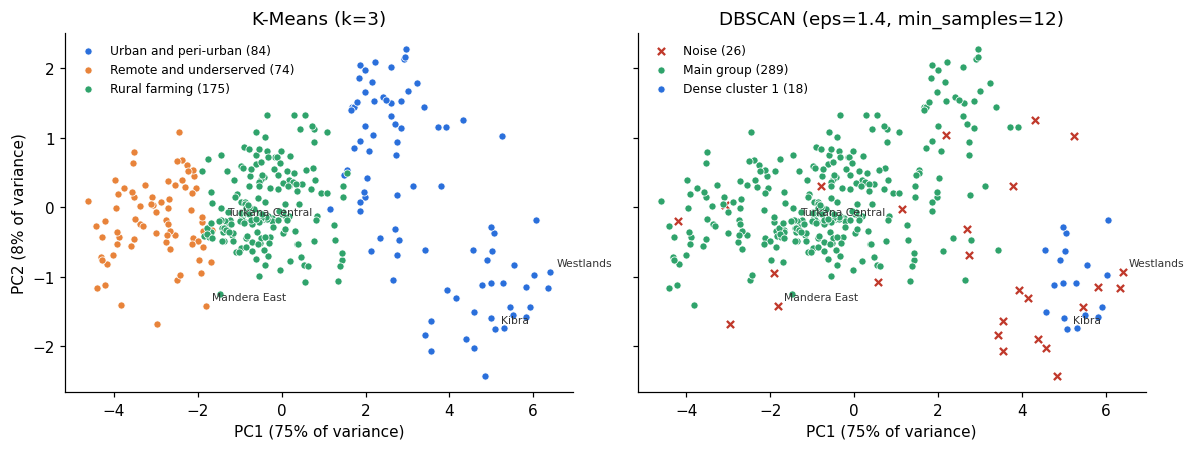

In [10]:
pca = PCA(2, random_state=SEED).fit(X); P = pca.transform(X)
ev = 100 * pca.explained_variance_ratio_
PAL = ['#2fa36b', '#2a6fdb', '#2fa36b', '#9b59b6']
KCOL = {'Urban and peri-urban': '#2a6fdb', 'Rural farming': '#2fa36b', 'Remote and underserved': '#e8833a'}
big = df.dbscan.value_counts().drop(-1, errors='ignore').idxmax()
DBNAMES = {c: ('Main group' if c == big else f'Dense cluster {c}') for c in set(df.dbscan) - {-1}}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for a, col, title in [(ax[0], 'kmeans', f'K-Means (k={K})'), (ax[1], 'dbscan', f'DBSCAN (eps={EPS}, min_samples={MSB})')]:
    for c in sorted(df[col].unique()):
        m = (df[col] == c).values
        if c == -1:
            a.scatter(P[m, 0], P[m, 1], s=22, marker='x', color='#c0392b', label=f'Noise ({m.sum()})')
        else:
            name = LABELS[c] if col == 'kmeans' else DBNAMES.get(c, f'Cluster {c}')
            color = KCOL[LABELS[c]] if col == 'kmeans' else PAL[c]
            a.scatter(P[m, 0], P[m, 1], s=22, color=color, edgecolor='white', linewidth=0.5, label=f'{name} ({m.sum()})')
    a.set(title=title, xlabel=f'PC1 ({ev[0]:.0f}% of variance)'); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel(f'PC2 ({ev[1]:.0f}% of variance)')
for name in ['Westlands', 'Mandera East', 'Turkana Central', 'Kibra', 'Laisamis']:
    i = np.where(df.subcounty.str.lower() == name.lower())[0]
    for a in ax:
        if len(i): a.annotate(name, P[i[0]], xytext=(4, 4), textcoords='offset points', fontsize=7, color='#333')
plt.tight_layout(); plt.savefig(FIG / 'clusters_pca.png', bbox_inches='tight'); plt.show()

## 9. What each cluster looks like
The average of each indicator is shown per cluster, using the original units. Example sub-counties are listed for each cluster.


kmeans cluster medians:
          n  density  household_size  under15_pct  electricity_pct  piped_water_pct  firewood_pct  internet_pct  mobile_phone_pct
kmeans                                                                                                                           
0        84    625.5             3.1         31.0             76.2             44.4          41.9          29.8              61.0
1        74     28.5             5.5         48.5              7.2              2.8          90.4           8.1              28.2
2       175    379.0             4.2         40.6             27.1              5.8          80.2          15.3              43.0
  kmeans 0: 20 counties, e.g. Embakasi (Nairobi City), Kasarani (Nairobi City), Njiru (Nairobi City), Dagoretti (Nairobi City), Ruiru (Kiambu), Naivasha (Nakuru)
  kmeans 1: 19 counties, e.g. Trans Mara West (Narok), Narok South (Narok), Turkana West (Turkana), Turkana Central (Turkana), Narok West (Narok), Lungalunga (Kwal

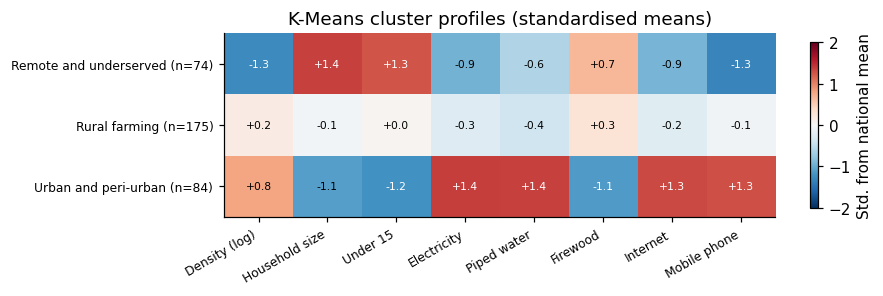


DBSCAN noise points (26):
      county     subcounty  density  household_size  under15_pct  electricity_pct  piped_water_pct  firewood_pct  internet_pct  mobile_phone_pct
Nairobi City       Mathare  68941.0             2.7         31.3             95.3             52.0           0.3          37.3              64.7
     Mombasa         Mvita  10543.0             3.8         28.9             91.1             12.9           1.3          55.2              66.4
Nairobi City       Starehe  10205.0             2.8         25.5             97.0             51.2           0.3          59.0              72.1
     Mombasa         Nyali   9610.0             3.1         30.4             87.9             13.3           2.2          44.9              65.7
     Mombasa     Changamwe   7457.0             2.8         30.4             87.7              8.2           1.6          39.9              65.3
     Mombasa        Likoni   6187.0             3.1         34.2             87.2              6.5     

In [11]:
SHOW = ['density', 'household_size', 'under15_pct', 'electricity_pct', 'piped_water_pct', 'firewood_pct', 'internet_pct', 'mobile_phone_pct']
for col in ['kmeans', 'dbscan']:
    prof = df.groupby(col)[SHOW].median().round(1); prof.insert(0, 'n', df[col].value_counts().sort_index())
    print(f'\n{col} cluster medians:'); print(prof.to_string())
    for c in sorted(df[col].unique()):
        g = df[df[col] == c].sort_values('households', ascending=False)
        print(f'  {col} {c}: {g.county.nunique()} counties, e.g.', ', '.join(g.subcounty.head(6) + ' (' + g.county.head(6) + ')'))
print('\nK-Means names:', LABELS)
z = pd.DataFrame(X, columns=FEATS).groupby(df.kmeans.values).mean().loc[order]
fig, ax = plt.subplots(figsize=(8.5, 2.8))
im = ax.imshow(z.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(FEATS)), ['Density (log)', 'Household size', 'Under 15', 'Electricity', 'Piped water', 'Firewood', 'Internet', 'Mobile phone'], rotation=30, ha='right', fontsize=8)
ax.set_yticks(range(K), [f'{LABELS[c]} (n={int((df.kmeans == c).sum())})' for c in order], fontsize=8)
for i in range(K):
    for j in range(len(FEATS)): ax.text(j, i, f'{z.values[i, j]:+.1f}', ha='center', va='center', fontsize=7, color='white' if abs(z.values[i, j]) > 1.1 else 'black')
plt.colorbar(im, ax=ax, label='Std. from national mean', shrink=0.9)
ax.set_title('K-Means cluster profiles (standardised means)')
plt.tight_layout(); plt.savefig(FIG / 'kmeans_profiles.png', bbox_inches='tight'); plt.show()
noise = df[df.dbscan == -1].sort_values('density', ascending=False)
print(f'\nDBSCAN noise points ({len(noise)}):'); print(noise[['county', 'subcounty'] + SHOW].head(25).round(1).to_string(index=False))

## 10. Save the results
The main numbers are written to `results.json` so the report can quote them exactly.

In [12]:
out = {'n_subcounties': int(len(df)), 'features': FEATS, 'k': K, 'eps': EPS, 'min_samples': MSB,
       'k_selection': ksel.round(4).reset_index().to_dict('records'),
       'metrics': res.round(4).reset_index().rename(columns={'index': 'model'}).to_dict('records'),
       'ari_kmeans_dbscan': round(float(ari), 4),
       'kmeans_sizes': df.kmeans.value_counts().sort_index().to_dict(),
       'dbscan_sizes': {int(k): int(v) for k, v in df.dbscan.value_counts().sort_index().items()},
       'kmeans_labels': {int(k): v for k, v in LABELS.items()},
       'pca_variance_pct': [round(float(e), 2) for e in ev]}
Path('results.json').write_text(json.dumps(out, indent=2, default=int))
df.to_csv(DATA / 'kenya_subcounty_2019_clusters.csv', index=False)
print(json.dumps({k: out[k] for k in ['n_subcounties', 'k', 'eps', 'min_samples', 'ari_kmeans_dbscan', 'kmeans_sizes', 'dbscan_sizes']}, default=int))

{"n_subcounties": 333, "k": 3, "eps": 1.4, "min_samples": 12, "ari_kmeans_dbscan": 0.1511, "kmeans_sizes": {"0": 84, "1": 74, "2": 175}, "dbscan_sizes": {"-1": 26, "0": 289, "1": 18}}
